# Detect depressurizations and split the flights into segments
Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

GAP_THRESH = pd.Timedelta(2, 'hours') # if the time step is larger than this threshold, the flight
                                      # is split into segments. I picked this low value of two hours 
                                      # to be conservative: as it is, 4.7% of data get deleted for a 
                                      # minimum segment length of 2 days. If I use a value of six
                                      # hours, that percentage is only reduced to 2.7.
MIN_SEG_LEN = pd.Timedelta(2, 'days') # the minimum segment length to be used in the analysis

In [2]:
# Load in the data
flights = pd.read_feather('Strateole2_with_ERA5_2_takeoffs_landings.feather')

# A time delta to fix a timestamping error from earlier (only for the C1 flights)
C1_Timedelta = pd.Timestamp('2019-01-01 00:00:00') - pd.Timestamp('2019-11-01 00:00:00')

In [3]:
# Mark depressurizations in the data
flights['depressurization'] = 0


# Flight C0_01_STR1
print('C0_01_STR1 number of data points in depressurization:')
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-05 10:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-05 11:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-06 08:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-06 12:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-08 10:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-08 14:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-15 14:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-15 16:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-17 10:45:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-17 17:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-25 13:15:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-25 18:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2020-01-09 08:45:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-09 13:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2020-01-11 15:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-11 18:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2020-01-13 07:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-13 14:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_01_STR1') & 
            (flights.time >= pd.Timestamp('2020-01-15 07:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-15 19:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
print()


# Flight C0_02_STR2
print('C0_02_STR2 number of data points in depressurization:')
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_02_STR2') & 
            (flights.time >= pd.Timestamp('2019-11-21 11:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-11-21 12:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_02_STR2') & 
            (flights.time >= pd.Timestamp('2019-12-09 10:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-09 16:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_02_STR2') & 
            (flights.time >= pd.Timestamp('2020-01-21 20:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-21 22:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_02_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-19 14:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-19 15:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C0_03_TTL3
print('C0_03_TTL3 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2019-11-22 20:15:00.00')) &
            (flights.time <= pd.Timestamp('2019-11-22 22:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2019-11-30 13:15:00.00')) &
            (flights.time <= pd.Timestamp('2019-11-30 14:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2019-12-14 09:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-14 17:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-01-08 01:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-08 02:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-01-09 00:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-09 03:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-01-28 15:10:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-28 16:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-01-28 21:15:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-29 00:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-01-30 11:20:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-30 13:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-01-31 18:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-31 19:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-02-01 12:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-01 13:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-02-02 11:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-02 13:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-02-03 13:15:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-03 16:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_03_TTL3') & 
            (flights.time >= pd.Timestamp('2020-02-08 07:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-08 13:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C0_04_TTL1
print('C0_04_TTL1 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C0_04_TTL1') & 
            (flights.time >= pd.Timestamp('2019-12-06 09:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-06 19:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_04_TTL1') & 
            (flights.time >= pd.Timestamp('2019-12-07 12:45:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-07 14:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_04_TTL1') & 
            (flights.time >= pd.Timestamp('2019-12-07 16:45:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-07 17:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_04_TTL1') & 
            (flights.time >= pd.Timestamp('2020-01-22 00:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-22 01:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C0_05_TTL2
print('C0_05_TTL2 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C0_05_TTL2') & 
            (flights.time >= pd.Timestamp('2019-12-14 15:15:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-14 17:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_05_TTL2') & 
            (flights.time >= pd.Timestamp('2019-12-17 15:35:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-17 17:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_05_TTL2') & 
            (flights.time >= pd.Timestamp('2019-12-21 16:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-21 19:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_05_TTL2') & 
            (flights.time >= pd.Timestamp('2019-12-23 16:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-23 18:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_05_TTL2') & 
            (flights.time >= pd.Timestamp('2020-01-28 19:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-29 00:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_05_TTL2') & 
            (flights.time >= pd.Timestamp('2020-02-02 11:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-02 12:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C0_06_STR1
print('C0_06_STR1 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-11 16:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-11 17:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-20 17:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-20 19:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-21 15:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-21 18:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-22 13:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-22 19:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-23 09:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-23 13:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-23 16:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-23 16:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-23 17:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-23 19:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-24 06:30:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-24 16:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2019-12-25 06:15:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-25 07:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2020-01-22 01:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-22 01:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_06_STR1') & 
            (flights.time >= pd.Timestamp('2020-01-22 03:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-01-22 04:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C0_07_STR2
print('C0_07_STR2 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C0_07_STR2') & 
            (flights.time >= pd.Timestamp('2019-12-22 13:00:00.00')) &
            (flights.time <= pd.Timestamp('2019-12-22 13:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_07_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-04 01:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-04 03:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C0_08_STR2
print('C0_08_STR2 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C0_08_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-03 07:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-03 08:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_08_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-03 08:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-03 09:15:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_08_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-03 16:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-03 16:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_08_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-04 08:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-04 09:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_08_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-04 11:30:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-04 12:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C0_08_STR2') & 
            (flights.time >= pd.Timestamp('2020-02-04 15:00:00.00')) &
            (flights.time <= pd.Timestamp('2020-02-04 18:30:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_02_STR1
print('C1_02_STR1 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_02_STR1') & 
            (flights.time >= pd.Timestamp('2022-08-24 21:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-24 23:20:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_02_STR1') & 
            (flights.time >= pd.Timestamp('2022-08-31 10:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-31 11:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_02_STR1') & 
            (flights.time >= pd.Timestamp('2022-08-31 12:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-31 12:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_02_STR1') & 
            (flights.time >= pd.Timestamp('2022-08-31 13:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-31 15:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_03_TTL4
print('C1_03_TTL4 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_03_TTL4') & 
            (flights.time >= pd.Timestamp('2022-08-22 17:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-22 19:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_03_TTL4') & 
            (flights.time >= pd.Timestamp('2022-08-24 23:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-25 00:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_03_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-20 22:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-20 23:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_04_STR2
print('C1_04_STR2 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-23 12:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-23 13:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-23 21:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-23 22:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-24 12:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-24 13:40:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-24 12:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-24 13:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-24 14:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-24 15:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-25 14:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-25 15:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_04_STR2') & 
            (flights.time >= pd.Timestamp('2022-08-26 11:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-08-26 13:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_05_TTL3
print('C1_05_TTL3 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_05_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-04 10:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-04 11:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_05_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-19 07:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-19 14:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_05_TTL3') & 
            (flights.time >= pd.Timestamp('2022-10-15 10:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-15 11:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_06_TTL5
print('C1_06_TTL5 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_06_TTL5') & 
            (flights.time >= pd.Timestamp('2022-09-30 15:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-30 16:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_07_TTL4
print('C1_07_TTL4 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-06 20:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-06 20:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-08 12:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-08 18:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-10 12:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-10 15:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-13 12:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-13 17:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-20 16:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-20 21:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-22 10:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-22 11:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-30 14:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-30 19:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-08 20:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-08 21:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-12 09:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-12 11:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-13 09:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-13 12:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_07_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-14 08:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-14 14:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_08_STR1
print('C1_08_STR1 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_08_STR1') & 
            (flights.time >= pd.Timestamp('2022-09-16 21:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-16 22:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_08_STR1') & 
            (flights.time >= pd.Timestamp('2022-09-21 10:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-21 11:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_08_STR1') & 
            (flights.time >= pd.Timestamp('2022-09-27 13:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-27 17:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_10_TTL3
print('C1_10_TTL3 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_10_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-17 13:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-17 17:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_10_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-19 10:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-19 16:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_10_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-21 17:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-21 21:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_10_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-25 08:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-25 09:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_10_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-25 11:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-25 12:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_10_TTL3') & 
            (flights.time >= pd.Timestamp('2022-09-29 14:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-29 15:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_11_TTL1
print('C1_11_TTL1 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_11_TTL1') & 
            (flights.time >= pd.Timestamp('2022-09-18 11:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-18 12:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_11_TTL1') & 
            (flights.time >= pd.Timestamp('2022-09-19 10:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-19 13:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_11_TTL1') & 
            (flights.time >= pd.Timestamp('2022-09-29 09:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-29 12:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_12_STR4
print('C1_12_STR4 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_12_STR4') & 
            (flights.time >= pd.Timestamp('2022-09-18 18:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-18 19:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_12_STR4') & 
            (flights.time >= pd.Timestamp('2022-09-25 10:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-25 13:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_12_STR4') & 
            (flights.time >= pd.Timestamp('2022-09-29 19:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-29 21:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_13_STR1
print('C1_13_STR1 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_13_STR1') & 
            (flights.time >= pd.Timestamp('2022-09-18 17:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-18 18:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_13_STR1') & 
            (flights.time >= pd.Timestamp('2022-09-26 19:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-26 20:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_13_STR1') & 
            (flights.time >= pd.Timestamp('2022-09-26 21:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-26 22:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_15_TTL4
print('C1_15_TTL4 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-09-29 19:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-29 20:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-05 11:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-05 19:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-07 13:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-07 16:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-07 18:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-07 21:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-12 18:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-12 21:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-10-13 14:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-13 20:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-11-09 03:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-11-09 04:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-11-09 06:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-11-09 08:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-11-09 08:20:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-11-09 09:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_15_TTL4') & 
            (flights.time >= pd.Timestamp('2022-11-09 09:25:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-11-09 10:55:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_16_TTL5
print('C1_16_TTL5 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_16_TTL5') & 
            (flights.time >= pd.Timestamp('2022-09-29 19:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-09-29 22:00:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_16_TTL5') & 
            (flights.time >= pd.Timestamp('2022-10-03 10:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-03 11:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_16_TTL5') & 
            (flights.time >= pd.Timestamp('2022-10-03 19:40:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-03 21:50:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_16_TTL5') & 
            (flights.time >= pd.Timestamp('2022-10-11 14:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-11 15:10:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_16_TTL5') & 
            (flights.time >= pd.Timestamp('2022-10-11 15:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-11 16:15:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_16_TTL5') & 
            (flights.time >= pd.Timestamp('2022-10-11 16:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-11 17:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()


# Flight C1_17_TTL3
print('C1_17_TTL3 number of data points in depressurization:')
flights.loc[(flights.flight_id == 'C1_17_TTL3') & 
            (flights.time >= pd.Timestamp('2022-10-05 21:00:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-05 21:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_17_TTL3') & 
            (flights.time >= pd.Timestamp('2022-10-09 11:45:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-09 13:30:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_17_TTL3') & 
            (flights.time >= pd.Timestamp('2022-10-10 16:15:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-10 17:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == 'C1_17_TTL3') & 
            (flights.time >= pd.Timestamp('2022-10-11 14:30:00.00') + C1_Timedelta) &
            (flights.time <= pd.Timestamp('2022-10-11 16:45:00.00') + C1_Timedelta), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()

C0_01_STR1 number of data points in depressurization:
150
480
480
210
750
600
510
390
838
1439

C0_02_STR2 number of data points in depressurization:
210
720
180
120

C0_03_TTL3 number of data points in depressurization:
270
120
900
150
330
100
330
228
120
120
300
360
720

C0_04_TTL1 number of data points in depressurization:
950
176
120
120

C0_05_TTL2 number of data points in depressurization:
300
230
420
300
540
210

C0_06_STR1 number of data points in depressurization:
180
300
298
776
480
90
210
1144
120
90
150

C0_07_STR2 number of data points in depressurization:
60
180

C0_08_STR2 number of data points in depressurization:
90
90
30
120
120
416

C1_02_STR1 number of data points in depressurization:
219
150
58
210

C1_03_TTL4 number of data points in depressurization:
180
60
90

C1_04_STR2 number of data points in depressurization:
150
120
200
10
90
120
180

C1_05_TTL3 number of data points in depressurization:
120
780
148

C1_06_TTL5 number of data points in depressurization:
60


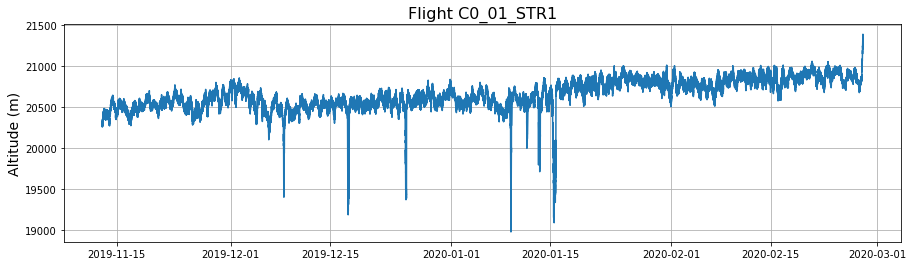

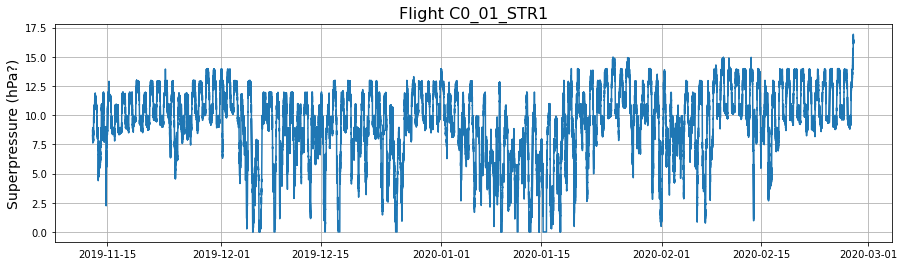

In [59]:
# Look for depressurizations

# Select a flight and zoom in on a specified time interval
flight_ids = flights.flight_id.unique()
flight_ind = 0

flight = flights[flights.flight_id == flight_ids[flight_ind]]
time_start = flight.time.iloc[0]
time_stop = flight.time.iloc[-1]
#time_start = pd.Timestamp('2020-01-09 00:00:00.00')
#time_stop = pd.Timestamp('2020-01-19 00:00:00.00')
#time_start = pd.Timestamp('2020-01-17 12:00:00.00')
#time_stop = pd.Timestamp('2020-01-17 23:00:00.00')
flight = flight[flight.time >= time_start]
flight = flight[flight.time <= time_stop]


plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.altitude)
plt.grid()
plt.title(f'Flight {flight_ids[flight_ind]}', fontsize=16)
plt.ylabel('Altitude (m)', fontsize=14);

plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.superpressure)
plt.grid()
plt.title(f'Flight {flight_ids[flight_ind]}', fontsize=16)
plt.ylabel('Superpressure (hPa?)', fontsize=14);

In [4]:
# Delete data marked as depressurizations, identify any data gaps, and if those gaps are larger than GAP_THRESH,
# split the flight into segments

def segments_from_gaps(flight):
    
    # Create a counter so that the segment ID is incremented across the flights, creating unique segment IDs
    if "counter" not in segments_from_gaps.__dict__:
        segments_from_gaps.counter = 0
        
    # Identify the time steps that are larger than GAP_THRESH
    flight['segment_id'] = (flight.time.diff() > GAP_THRESH).astype(int).cumsum()
    n_segments = flight.segment_id.max() + 1 # the segments start at zero
        
    # Apply the counter and increment it
    flight.segment_id = flight.segment_id + segments_from_gaps.counter
    segments_from_gaps.counter = segments_from_gaps.counter + n_segments
    
    return flight

# Delete depressurizations
print('Deleting depressurizations')
flights = flights[flights.depressurization == 0]
flights = flights.drop(columns = 'depressurization')

# Split flights into segments when the data gap is too big
print('Splitting the flights into segments')
flights = flights.groupby('flight_id').apply(segments_from_gaps).reset_index(drop=True)
print(f'Number of segments: {flights.segment_id.nunique()}')
print()

# Delete segments that are too short
print('Calculating segment length')
n_data_before = flights.shape[0]
num_before = flights.segment_id.nunique()
segment_length = flights.groupby('segment_id').apply(lambda f: f.time.iloc[-1] - f.time.iloc[0])
segments_tooshort = segment_length[segment_length < MIN_SEG_LEN]
flights = flights[~flights.segment_id.isin(segments_tooshort.index)].reset_index(drop=True)
print(f'Removed {num_before-flights.segment_id.nunique()}/{num_before} segments that are too short')
print(f'Deleted {100*(n_data_before - flights.shape[0])/n_data_before} percent of the data')
print()

Deleting depressurizations
Splitting the flights into segments
Number of segments: 75

Calculating segment length
Removed 18/75 segments that are too short
Deleted 1.6510454894941153 percent of the data



In [5]:
# Save the data
flights.to_feather('Strateole2_with_ERA5_3_depressurizations.feather') 
flights

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure,segment_id
0,C0_01_STR1,2019-11-12 22:25:07.005612,-4.834385,55.593623,20306.0,NaN,NaN,53.838274,203.456487,0.000691,8.270000,0
1,C0_01_STR1,2019-11-12 22:25:37.076783,-4.836663,55.593735,20297.0,0.361103,-8.387708,53.902477,203.428319,0.000691,8.270000,0
2,C0_01_STR1,2019-11-12 22:26:07.026208,-4.838898,55.593818,20297.0,0.256162,-8.362772,53.893533,203.432243,0.000691,8.200000,0
3,C0_01_STR1,2019-11-12 22:26:37.098505,-4.841163,55.593873,20305.0,0.200608,-8.576493,53.804733,203.471199,0.000691,8.200000,0
4,C0_01_STR1,2019-11-12 22:27:07.047890,-4.843513,55.593927,20306.0,0.188386,-8.961514,53.773176,203.485038,0.000691,8.770000,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3664718,C1_17_TTL3,2021-12-16 12:31:57.000000,-2.211255,125.868032,18601.4,-3.421231,2.695646,71.513419,191.921589,0.000809,10.187500,74
3664719,C1_17_TTL3,2021-12-16 12:32:27.000000,-2.210570,125.867093,18591.3,-3.461483,2.463263,71.650113,191.897698,0.000808,9.933594,74
3664720,C1_17_TTL3,2021-12-16 12:32:57.000000,-2.209930,125.866168,18597.9,-3.272620,2.364113,71.578122,191.910271,0.000809,9.821289,74
3664721,C1_17_TTL3,2021-12-16 12:33:27.000000,-2.209298,125.865332,18611.9,-2.845354,2.463263,71.404752,191.940639,0.000809,9.756836,74
